# Plot the MW population per formation channel


## imports

In [7]:
from posydon.utils.common_functions import convert_metallicity_to_string, orbital_separation_from_period
import matplotlib.pyplot as plt
import numpy as np

from cmap import Colormap
import pickle
from pathlib import Path
from tqdm import tqdm
from scipy.stats import gaussian_kde

# custom helper scripts
from helper_functions import calc_Teff, optical_depth_calculation

tol_vibrant = Colormap('tol:vibrant')(np.linspace(0, 1, 7))

## Load POSYDON data

In [8]:
data_folder = Path('/Users/max/Documents/projects/WR_population/data/optical_depth/')
metallicity = 1.0
met_str = convert_metallicity_to_string(metallicity)
file_path = data_folder / f'WR_phases_Z{met_str}_Zsun.pkl'
with open(file_path, 'rb') as f:
    data = pickle.load(f)
    
S1_WR_data = data['S1_WR_data']
S2_WR_data = data['S2_WR_data']


In [9]:
import pandas as pd

# Concatenate all per-key DataFrames at once (much faster than per-key extend loops)
s1 = pd.concat(S1_WR_data.values(), keys=S1_WR_data.keys())
s2 = pd.concat(S2_WR_data.values(), keys=S2_WR_data.keys())

# Compute derived quantities vectorized over full DataFrames
s1_Teff = 10**calc_Teff(s1['S1_log_L'], s1['S1_log_R'])
s1_sep  = orbital_separation_from_period(s1['orbital_period'].values,
                                          s1['S1_mass'].values,
                                          s1['S2_mass'].values)

s2_Teff = 10**calc_Teff(s2['S2_log_L'], s2['S2_log_R'])
s2_sep  = orbital_separation_from_period(s2['orbital_period'].values,
                                          s2['S2_mass'].values,
                                          s2['S1_mass'].values)

# Extract final arrays
time_array           = np.concatenate([s1['time'].values,          s2['time'].values])
weight_array         = np.concatenate([s1['weight'].values,        s2['weight'].values])
state_array          = np.concatenate([s1['state'].values,         s2['state'].values])
key_array            = np.concatenate([s1.index.get_level_values(0), s2.index.get_level_values(0)])
star_array           = np.array(['S1'] * len(s1) + ['S2'] * len(s2))
period_array         = np.concatenate([s1['orbital_period'].values, s2['orbital_period'].values])
separation_array     = np.concatenate([s1_sep,                      s2_sep])
Teff_array           = np.concatenate([s1_Teff.values,              s2_Teff.values])
L_array              = np.concatenate([10**s1['S1_log_L'].values,   10**s2['S2_log_L'].values])
optical_depth_array  = np.concatenate([s1['optical_depth'].values,  s2['optical_depth'].values])
surface_H_array      = np.concatenate([s1['S1_surface_h1'].values,  s2['S2_surface_h1'].values])
surface_He_array     = np.concatenate([s1['S1_surface_he4'].values, s2['S2_surface_he4'].values])
mass_array           = np.concatenate([s1['S1_mass'].values,        s2['S2_mass'].values])
mass_companion_array = np.concatenate([s1['S2_mass'].values,        s2['S1_mass'].values])
radius_array         = np.concatenate([10**s1['S1_log_R'].values,   10**s2['S2_log_R'].values])
Mdot_array           = np.concatenate([10**s1['S1_lg_mdot'].values, 10**s2['S2_lg_mdot'].values])
companion_array      = np.concatenate([s1['S2_state'].values,       s2['S1_state'].values])
S1_state_array       = np.concatenate([s1['S1_state'].values,       s2['S2_state'].values])
model_weight_array   = np.concatenate([s1['model_weight'].values,  s2['model_weight'].values])


In [10]:
# hydrogen poor
WNL =  (surface_H_array > 0.05) & (surface_H_array <= 0.5) & (optical_depth_array > 1.5) & ~pd.Series(S1_state_array).str.contains('H_burning', na=False).values
# Hydrogen free
WNE = (surface_H_array <= 0.05) & (surface_He_array >= 0.7) & (optical_depth_array > 1.5)
WC = (surface_H_array <= 0.05) & (surface_He_array < 0.7) & (optical_depth_array > 1.5)

In [11]:
binary_mask = (state_array == 'detached') | (state_array == 'RLO1') | (state_array == 'contact') | (state_array == 'RLO2')

In [12]:
WNL_fraction = np.sum(weight_array[binary_mask & WNL])/np.sum(weight_array[binary_mask & (WNL | WNE | WC)])
WNE_fraction = np.sum(weight_array[binary_mask & WNE])/np.sum(weight_array[binary_mask & (WNL | WNE | WC)])
WC_fraction = np.sum(weight_array[binary_mask & WC])/np.sum(weight_array[binary_mask & (WNL | WNE | WC)])
print(f"WNL (H-poor): {WNL_fraction*100:.0f}%")
print(f"WNE (H-free): {WNE_fraction*100:.0f}%")
print(f"WC: {WC_fraction*100:.0f}%")

WNL (H-poor): 16%
WNE (H-free): 55%
WC: 29%


## load observations

In [13]:
import json

with open('/Users/max/Documents/projects/WR_population/data/observations/Galactic_WRs.json', 'r') as f:
    observational_data = json.load(f)


In [14]:
obs_df = pd.DataFrame.from_dict(observational_data, orient='index')
obs_df.index.name = 'WR_name'

# Unpack [lower, value, upper] list columns into separate _err_lo, _val, _err_hi columns
list_cols = ['Period', 'Eccentricity', 'M1', 'M2', 'Mass Function', 'M1_sin3i', 'M2_sin3i', 'RA', 'Dec']
for col in list_cols:
    if col in obs_df.columns:
        unpacked = pd.DataFrame(obs_df[col].tolist(), index=obs_df.index,
                                columns=[f'{col}_err_lo', col, f'{col}_err_hi'])
        obs_df = obs_df.drop(columns=col).join(unpacked)



In [11]:
mask = obs_df['Period'] > 10**2.5
obs_df[['Eccentricity', 'Period']]


,Eccentricity,Period
WR_name,,
WR 9,0.0000,14.305000
WR 11,0.3340,78.530000
WR 19,0.8000,3689.000000
WR 21,0.0400,8.254600
WR 29,0.0000,3.164150
WR 30,NaN,18.820000
WR 30a,0.1500,4.620000
WR 31,0.0000,4.830657
WR 35a,0.0000,41.898000


In [12]:
obs_df.loc[~mask, 'Eccentricity']


WR_name
WR 9       0.0000
WR 11      0.3340
WR 21      0.0400
WR 29      0.0000
WR 30         NaN
WR 30a     0.1500
WR 31      0.0000
WR 35a     0.0000
WR 42      0.0000
WR 47      0.0000
WR 48      0.0000
WR 62a     0.0000
WR 68a     0.0000
WR 79         NaN
WR 97      0.0000
WR 104     0.0000
WR 113     0.0000
WR 127     0.0000
WR 133     0.3558
WR 139     0.0000
WR 145a    0.0000
WR 151     0.0000
WR 155     0.0100
Name: Eccentricity, dtype: float64

In [15]:
LOG_P_MIN, LOG_P_MAX = -1, 6  # shared x-range in log10(P)
OBS_N_BINS = 50             # number of bins for the observations PMF

def plot_observations(obs_df, ax, **kwargs):
    """Plot observed period distribution as a PMF in log10(P) space.
    Multiply KDE evaluations by BIN_WIDTH to put them on the same scale."""
    log_periods = np.log10(obs_df['Period'].dropna().astype(float))
    bins = np.linspace(LOG_P_MIN, LOG_P_MAX, OBS_N_BINS + 1)
    h, edges = np.histogram(log_periods, bins=bins,
                            density=True)
    ax.fill_between(10**edges[:-1], h*0.5, step='post', alpha=0.2, color='black',
                    zorder=10, label='Observations', edgecolor='none', **kwargs)
    ax.step(10**edges[:-1], h*0.5, where='post', color='black', linewidth=1,
            zorder=11, alpha=0.6)
    
    # Rug plot: individual tick marks at the top of the axes
    # ylim = ax.get_ylim()
    # rug_frac = 0.03
    # for lp in log_periods:
    #     ax.axvline(10**lp, ymin=1 - rug_frac, ymax=1, color='black',
    #                linewidth=1, alpha=0.7, zorder=12, clip_on=False)


In [16]:
from posydon.popsyn.synthetic_population import Population
import pandas as pd
population_run_folder = Path('/Users/max/Documents/projects/WR_population/population_synthesis/runs/2026_08_14/')
population_file = population_run_folder / f"{met_str}_Zsun_population.h5"

pop = Population(str(population_file))

HMS_HMS_interaction = pop.oneline['interp_class_HMS_HMS']
CO_HMS_RLO_interaction = pop.oneline['interp_class_CO_HMS_RLO']

S1_stable_indices = set(np.where(HMS_HMS_interaction == 'stable_MT')[0])
S1_unstable_indices = set(np.where(HMS_HMS_interaction == 'unstable_MT')[0])
S1_reverse_stable_indices = set(np.where(HMS_HMS_interaction == 'reverse_stable_MT')[0])
S1_no_MT_indices = set(np.where((HMS_HMS_interaction == 'no_MT') | pd.isna(HMS_HMS_interaction))[0])

# S1 interaction masks - only apply to S1 entries
S1_entries = (star_array == 'S1')
S1_mask_stable = S1_entries & np.isin(key_array, np.array(list(S1_stable_indices)))
S1_mask_unstable = S1_entries & np.isin(key_array, np.array(list(S1_unstable_indices)))
S1_mask_reverse_stable = S1_entries & np.isin(key_array, np.array(list(S1_reverse_stable_indices)))
S1_mask_no_MT = S1_entries & np.isin(key_array, np.array(list(S1_no_MT_indices)))


S2_stable_indices = set(np.where(CO_HMS_RLO_interaction == 'stable_MT')[0])
S2_unstable_indices = set(np.where(CO_HMS_RLO_interaction == 'unstable_MT')[0])
S2_reverse_stable_indices = set(np.where(CO_HMS_RLO_interaction == 'reverse_stable_MT')[0])
S2_no_MT_indices = set(np.where((CO_HMS_RLO_interaction == 'no_MT') | pd.isna(CO_HMS_RLO_interaction))[0])

# S2 interaction masks - only apply to S2 entries
S2_entries = (star_array == 'S2')
S2_mask_stable = S2_entries & np.isin(key_array, np.array(list(S2_stable_indices)))
S2_mask_unstable = S2_entries & np.isin(key_array, np.array(list(S2_unstable_indices)))
S2_mask_reverse_stable = S2_entries & np.isin(key_array, np.array(list(S2_reverse_stable_indices)))
S2_mask_no_MT = S2_entries & np.isin(key_array, np.array(list(S2_no_MT_indices)))

# Sana+12 period distribution

WNL: 0.13651619101800175
Stable (S1): 0.491
Stable (S2): 0.217
Unstable (S1): 0.009
Unstable (S2): 0.000
No MT (S1): 0.103
No MT (S2): 0.135
WNE: 0.581491946664158
Stable (S1): 0.451
Stable (S2): 0.157
Unstable (S1): 0.017
Unstable (S2): 0.039
No MT (S1): 0.239
No MT (S2): 0.070
WC: 0.2819918623178412
Stable (S1): 0.315
Stable (S2): 0.084
Unstable (S1): 0.011
Unstable (S2): 0.040
No MT (S1): 0.359
No MT (S2): 0.174


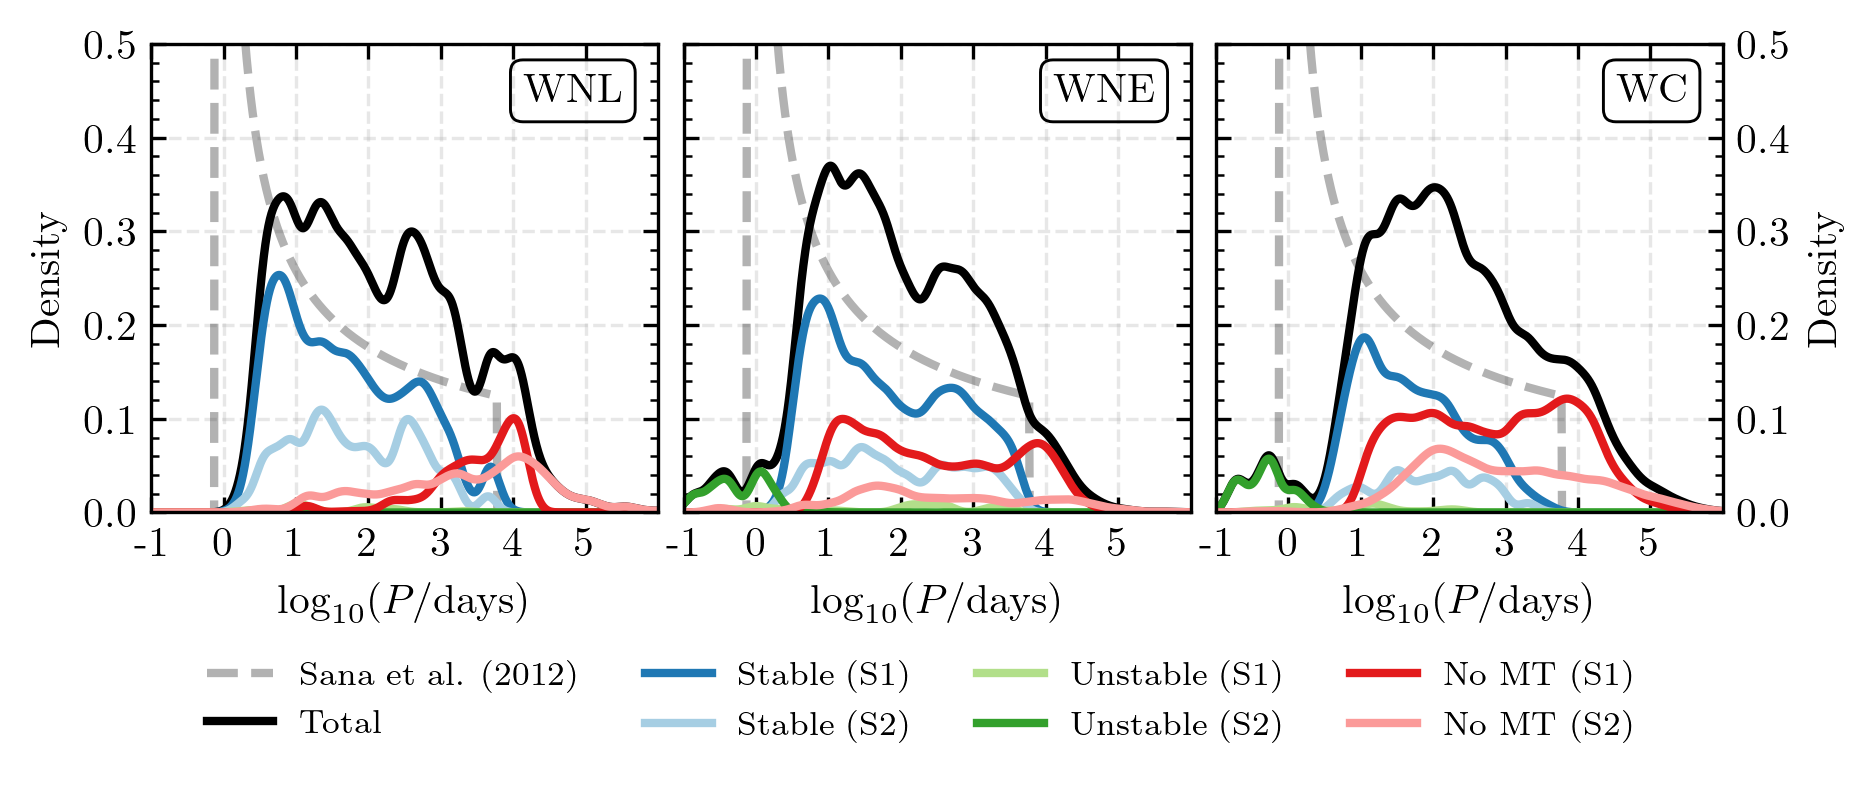

In [17]:
from posydon.popsyn.distributions import Sana12Period

fig, axes = plt.subplots(1, 3, figsize=(3.38*2, 2.535*0.8))

x_eval = np.linspace(-1, 6, 1000)
sana_dist = Sana12Period(p_min=0.75, p_max=6000.0)
weights = np.where(np.isclose(model_weight_array,0.0), 0, weight_array)

mask = binary_mask

MT_interactions = {'Stable (S1)': S1_mask_stable,
                   'Stable (S2)': S2_mask_stable,
                   'Unstable (S1)': S1_mask_unstable,
                   'Unstable (S2)': S2_mask_unstable,
                   'No MT (S1)': S1_mask_no_MT,
                   'No MT (S2)': S2_mask_no_MT,
                   'Reverse Stable (S1)': S1_mask_reverse_stable,}


colours = Colormap('colorbrewer:Paired_8')(np.linspace(0,1,8))

colours = {"Stable (S1)": colours[1],
           "Stable (S2)": colours[0],

           "Unstable (S1)": colours[2],
           "Unstable (S2)": colours[3],

           "No MT (S1)": colours[5],
           "No MT (S2)": colours[4],
           
           "Reverse Stable (S1)": colours[7],
           }


# Setup Sana+12 distribution
m_wr_progenitor = 20.0
period_eval = 10**x_eval
sana_pdf = sana_dist.pdf(period_eval, m_wr_progenitor)
for ax in axes:
    ax.plot(10**x_eval, sana_pdf, 'k--', linewidth=2, alpha=0.3, 
         label=f'Sana et al. (2012)')





# plot WNL
kde = gaussian_kde(np.log10(period_array[mask & WNL]), weights=weights[mask & WNL], bw_method=0.1)
kde_eval = kde(x_eval)
axes[0].plot(10**x_eval, kde_eval, color='black', label='Total', linewidth=2)

# get covariance
cho_cov = kde.cho_cov

# different MT interactions
print("WNL:", weights[mask & WNL].sum()/weights[mask & (WNL | WNE | WC)].sum())
total = 0
not_used_mask = np.ones_like(mask, dtype=bool)  # Track which data points have been used in KDEs
for label, mt_mask in MT_interactions.items():
    if np.sum(weights[mask & WNL & mt_mask]) == 0:
        continue  # Skip if no data points for this interaction type
    kde = gaussian_kde(np.log10(period_array[mask & WNL & mt_mask]), weights=weights[mask & WNL & mt_mask], bw_method=0.1)
    kde.cho_cov = cho_cov # use same covariance for all KDEs to ensure fair comparison
    kde_eval = kde(x_eval)
    fraction = np.sum(weights[mask & WNL & mt_mask]) / np.sum(weights[mask & WNL])
    total += fraction
    print(f"{label}: {fraction:.3f}")
    axes[0].plot(10**x_eval, kde_eval*fraction, label=label, linewidth=2, color=colours[label])

# Plot WNE
kde = gaussian_kde(np.log10(period_array[mask & WNE]), weights=weights[mask & WNE], bw_method=0.1)
cho_cov = kde.cho_cov # get covariance to use for all WNE KDEs
kde_eval = kde(x_eval)
axes[1].plot(10**x_eval, kde_eval, color='black', label='Total', linewidth=2)

print("WNE:", weights[mask & WNE].sum()/weights[mask & (WNL | WNE | WC)].sum())
for label, mt_mask in MT_interactions.items():
    if np.sum(weights[mask & WNE & mt_mask]) == 0:
        continue  # Skip if no data points for this interaction type
    kde = gaussian_kde(np.log10(period_array[mask & WNE & mt_mask]), weights=weights[mask & WNE & mt_mask], bw_method=0.1)
    kde.cho_cov = cho_cov # use same covariance for all KDEs to ensure fair comparison
    kde_eval = kde(x_eval)
    fraction = np.sum(weights[mask & WNE & mt_mask]) / np.sum(weights[mask & WNE])
    print(f"{label}: {fraction:.3f}")
    axes[1].plot(10**x_eval, kde_eval*fraction, label=label, linewidth=2, color=colours[label])


# plot WC
kde = gaussian_kde(np.log10(period_array[mask & WC]), weights=weights[mask & WC], bw_method=0.1)
cho_cov = kde.cho_cov # get covariance to use for all WC KDEs
kde_eval = kde(x_eval)
axes[2].plot(10**x_eval, kde_eval, color='black', label='Total', linewidth=2)

print("WC:", weights[mask & WC].sum()/weights[mask & (WNL | WNE | WC)].sum())
for label, mt_mask in MT_interactions.items():
    if np.sum(weights[mask & WC & mt_mask]) == 0:
        continue  # Skip if no data points for this interaction type
    kde = gaussian_kde(np.log10(period_array[mask & WC & mt_mask]), weights=weights[mask & WC & mt_mask], bw_method=0.1)
    kde.cho_cov = cho_cov # use same covariance for all KDEs to ensure fair comparison
    kde_eval = kde(x_eval)
    fraction = np.sum(weights[mask & WC & mt_mask]) / np.sum(weights[mask & WC])
    print(f"{label}: {fraction:.3f}")
    axes[2].plot(10**x_eval, kde_eval*fraction, label=label, linewidth=2, color=colours[label])


# Housekeeping for layout

for ax in axes:
    ax.set_xlabel('$\log_{10}(P/\mathrm{days})$')
    ax.set_xscale('log')
    ax.set_xlim(1e-1, 1e6)
    ax.set_xticks([0.1, 1, 10, 100, 1000, 10000, 100000])
    ax.set_xticklabels(['-1', '0', '1', '2', '3', '4', '5'])
    ax.set_ylim(0, 0.5)
    ax.grid(True, which='major', ls='--', alpha=0.3)
    

axes[0].set_ylabel('Density')
axes[1].legend(loc='upper left', bbox_to_anchor=(-1, -0.25), ncol=4)

axes[1].set_yticklabels([])
# move ytick label to right side for right plot
axes[-1].set_ylabel('Density')
axes[-1].yaxis.set_label_position("right")
axes[-1].yaxis.set_tick_params(left=True, right=True, labelleft=False, labelright=True)

axes[0].text(0.93, 0.9, 'WNL', transform=axes[0].transAxes, ha='right', va='center',
             bbox=dict(facecolor='none', edgecolor='black', boxstyle='round, pad=0.3', lw=0.7))
axes[1].text(0.93, 0.9, 'WNE', transform=axes[1].transAxes, ha='right', va='center',
             bbox=dict(facecolor='none', edgecolor='black', boxstyle='round, pad=0.3', lw=0.7))
axes[2].text(0.93, 0.9, 'WC', transform=axes[2].transAxes, ha='right', va='center',
             bbox=dict(facecolor='none', edgecolor='black', boxstyle='round, pad=0.3', lw=0.7))

plt.subplots_adjust(wspace=0.05)

figure_paths = '/Users/max/Documents/projects/WR_population/figure_scripts/extra_figures/'
plt.savefig(figure_paths + 'pdf/MW_subtype_period_distributions_MT_Sana+12.pdf', bbox_inches='tight')
plt.savefig(figure_paths + 'png/MW_subtype_period_distributions_MT_Sana+12.png', bbox_inches='tight', dpi=300)
plt.show()

In [18]:
weights = np.where(np.isclose(model_weight_array,0.0), weight_array, 0)

(16336097,)
(16336097,)
WNL: 1.0
Stable (S1): 0.418
Stable (S2): 0.145
Unstable (S1): 0.014
Unstable (S2): 0.034
No MT (S1): 0.254
No MT (S2): 0.108


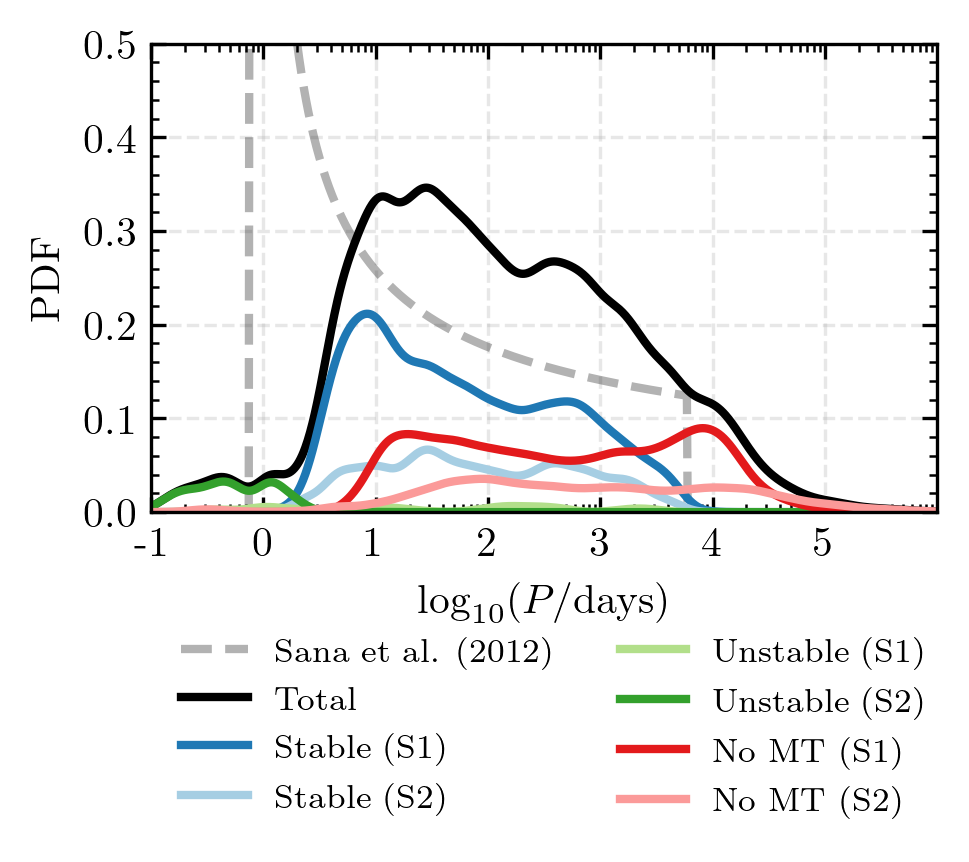

In [19]:
from posydon.popsyn.distributions import Sana12Period

fig, ax = plt.subplots(1, 1, figsize=(3.38, 2.535*0.8))

x_eval = np.linspace(-1, 6, 1000)
sana_dist = Sana12Period(p_min=0.75, p_max=6000.0)
weights = np.where(np.isclose(model_weight_array,0.0), 0, weight_array)

mask = binary_mask

MT_interactions = {'Stable (S1)': S1_mask_stable,
                   'Stable (S2)': S2_mask_stable,
                   'Unstable (S1)': S1_mask_unstable,
                   'Unstable (S2)': S2_mask_unstable,
                   'No MT (S1)': S1_mask_no_MT,
                   'No MT (S2)': S2_mask_no_MT,
                   'Reverse Stable (S1)': S1_mask_reverse_stable,}


colours = Colormap('colorbrewer:Paired_8')(np.linspace(0,1,8))

colours = {"Stable (S1)": colours[1],
           "Stable (S2)": colours[0],

           "Unstable (S1)": colours[2],
           "Unstable (S2)": colours[3],

           "No MT (S1)": colours[5],
           "No MT (S2)": colours[4],
           
           "Reverse Stable (S1)": colours[7],
           }


# Setup Sana+12 distribution
m_wr_progenitor = 20.0
period_eval = 10**x_eval
sana_pdf = sana_dist.pdf(period_eval, m_wr_progenitor)
ax.plot(10**x_eval, sana_pdf, 'k--', linewidth=2, alpha=0.3, 
         label=f'Sana et al. (2012)')



print(period_array[mask].shape)
print(weights[mask].shape)

# plot WNL
kde = gaussian_kde(np.log10(period_array[mask & (WNL | WNE | WC)]), weights=weights[mask & (WNL | WNE | WC)], bw_method=0.1)
kde_eval = kde(x_eval)
ax.plot(10**x_eval, kde_eval, color='black', label='Total', linewidth=2)

# get covariance
cho_cov = kde.cho_cov

# different MT interactions
print("WNL:", weights[mask & (WNL | WNE | WC)].sum()/weights[mask & (WNL | WNE | WC)].sum())
total = 0
not_used_mask = np.ones_like(mask, dtype=bool)  # Track which data points have been used in KDEs
for label, mt_mask in MT_interactions.items():
    if np.sum(weights[mask & WNL & mt_mask]) == 0:
        continue  # Skip if no data points for this interaction type
    kde = gaussian_kde(np.log10(period_array[mask & (WNL | WNE | WC) & mt_mask]), weights=weights[mask & (WNL | WNE | WC) & mt_mask], bw_method=0.1)
    kde.cho_cov = cho_cov # use same covariance for all KDEs to ensure fair comparison
    kde_eval = kde(x_eval)
    fraction = np.sum(weights[mask & (WNL | WNE | WC) & mt_mask]) / np.sum(weights[mask & (WNL | WNE | WC)])
    total += fraction
    print(f"{label}: {fraction:.3f}")
    ax.plot(10**x_eval, kde_eval*fraction, label=label, linewidth=2, color=colours[label])

# Housekeeping for layout

ax.set_xlabel('$\log_{10}(P/\mathrm{days})$')
ax.set_xscale('log')
ax.set_xlim(1e-1, 1e6)
ax.set_xticks([0.1, 1, 10, 100, 1000, 10000, 100000])
ax.set_xticklabels(['-1', '0', '1', '2', '3', '4', '5'])
ax.set_ylim(0, 0.5)
ax.grid(True, which='major', ls='--', alpha=0.3)
    
ax.set_ylabel('PDF')

# axes[0].set_ylabel('Density')
# axes[1].legend(loc='upper left', bbox_to_anchor=(-1, -0.25), ncol=4)

# axes[1].set_yticklabels([])
# # move ytick label to right side for right plot
# axes[-1].set_ylabel('Density')
# axes[-1].yaxis.set_label_position("right")
# axes[-1].yaxis.set_tick_params(left=True, right=True, labelleft=False, labelright=True)

# axes[0].text(0.93, 0.9, 'WNL', transform=axes[0].transAxes, ha='right', va='center',
#              bbox=dict(facecolor='none', edgecolor='black', boxstyle='round, pad=0.3', lw=0.7))
# axes[1].text(0.93, 0.9, 'WNE', transform=axes[1].transAxes, ha='right', va='center',
#              bbox=dict(facecolor='none', edgecolor='black', boxstyle='round, pad=0.3', lw=0.7))
# axes[2].text(0.93, 0.9, 'WC', transform=axes[2].transAxes, ha='right', va='center',
#              bbox=dict(facecolor='none', edgecolor='black', boxstyle='round, pad=0.3', lw=0.7))

# plt.subplots_adjust(wspace=0.05)
ax.legend(bbox_to_anchor=(0.0, -0.2), loc='upper left', ncol=2)

figure_paths = '/Users/max/Documents/projects/WR_population/figure_scripts/extra_figures/'
plt.savefig(figure_paths + 'pdf/MW_WR_period_distributions_MT_Sana+12.pdf', bbox_inches='tight')
plt.savefig(figure_paths + 'png/MW_WR_period_distributions_MT_Sana+12.png', bbox_inches='tight', dpi=300)
plt.show()

# Flat log_{10}(P) distribution

WNL: 1.0
Interacting: 59.304%
Non-interacting: 37.798%


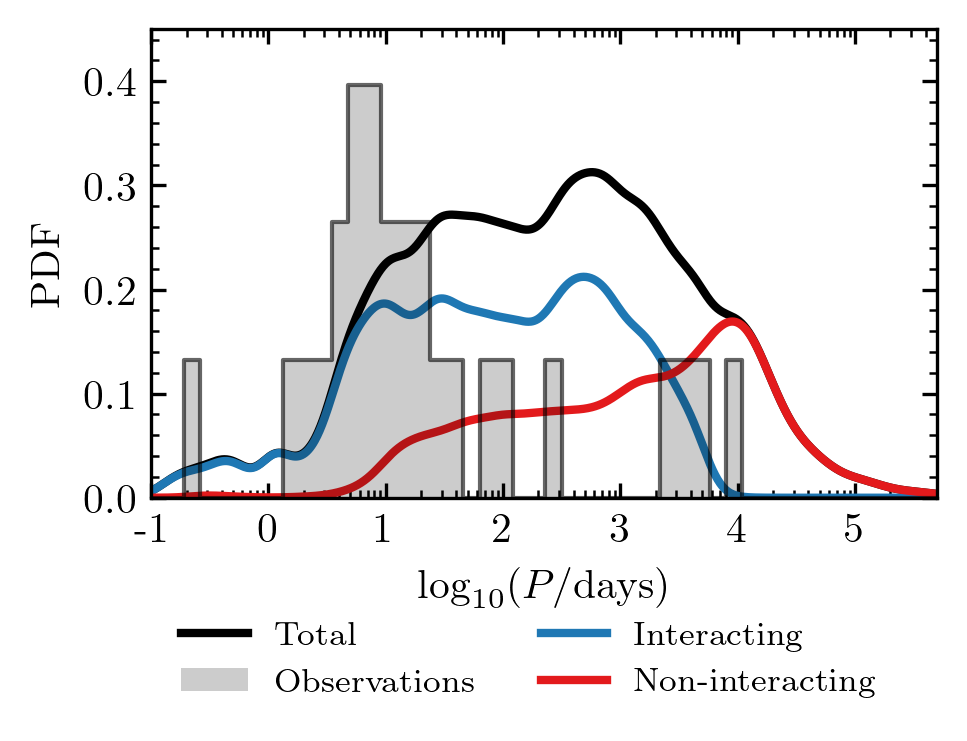

In [21]:
from posydon.popsyn.distributions import Sana12Period, PowerLawPeriod

weights = weight_array * model_weight_array

fig, ax = plt.subplots(1, 1, figsize=(3.38, 2.535*0.8))

PDF_logP = PowerLawPeriod(p_min=0.75, p_max=6000.0, slope=0.0)
x_eval = np.linspace(LOG_P_MIN, LOG_P_MAX, 1000)

mask = binary_mask

MT_interactions = {'Interacting' : S1_mask_stable | S2_mask_stable | S1_mask_unstable | S2_mask_unstable | S1_mask_reverse_stable | S2_mask_reverse_stable,
                   'Non-interacting' : S1_mask_no_MT | S2_mask_no_MT,}


colours = Colormap('colorbrewer:Paired_8')(np.linspace(0,1,8))

colours = {"Interacting": colours[1],
           "Non-interacting": colours[5],
           }


flatP = PDF_logP.pdf(10**x_eval)
#ax.plot(10**x_eval, flatP, ':',
#        color='black', linewidth=2, alpha=0.3, 
#         label=f'ZAMS distribution')


# plot WNL
kde = gaussian_kde(np.log10(period_array[mask & (WNL | WNE | WC)]), weights=weights[mask & (WNL | WNE | WC)], bw_method=0.1)
kde_eval = kde(x_eval)
ax.plot(10**x_eval, kde_eval, color='black', label='Total', linewidth=2)

plot_observations(obs_df,
                  ax=ax)

# get covariance
cho_cov = kde.cho_cov

# different MT interactions
print("WNL:", weights[mask & (WNL | WNE | WC)].sum()/weights[mask & (WNL | WNE | WC)].sum())
total = 0
not_used_mask = np.ones_like(mask, dtype=bool)  # Track which data points have been used in KDEs
for label, mt_mask in MT_interactions.items():
    if np.sum(weights[mask & WNL & mt_mask]) == 0:
        continue  # Skip if no data points for this interaction type
    
    # plot histogram 
    kde = gaussian_kde(np.log10(period_array[mask & (WNL | WNE | WC) & mt_mask]), weights=weights[mask & (WNL | WNE | WC) & mt_mask], bw_method=0.1)
    kde.cho_cov = cho_cov # use same covariance for all KDEs to ensure fair comparison
    kde_eval = kde(x_eval)
    fraction = np.sum(weights[mask & (WNL | WNE | WC) & mt_mask]) / np.sum(weights[mask & (WNL | WNE | WC)])
    total += fraction
    print(f"{label}: {fraction*100:.3f}%")
    ax.plot(10**x_eval, kde_eval*fraction, label=label, linewidth=2, color=colours[label])




# Housekeeping for layout
ax.set_xlabel('$\log_{10}(P/\mathrm{days})$')
ax.set_xscale('log')
ax.set_xlim(1e-1, 5e5)
ax.set_xticks([0.1, 1, 10, 100, 1000, 10000, 100000])
ax.set_xticklabels(['-1', '0', '1', '2', '3', '4', '5'])
ax.set_ylim(0, 0.45)
ax.grid(False)
#ax.grid(True, which='major', ls='--', alpha=0.3)
    
ax.set_ylabel('PDF')

ax.legend(bbox_to_anchor=(0.0, -0.2), loc='upper left', ncol=2)

figure_paths = '/Users/max/Documents/projects/WR_population/figure_scripts/figures/'
plt.savefig(figure_paths + 'pdf/MW_WR_period_distributions_MT_basic.pdf', bbox_inches='tight')
plt.savefig(figure_paths + 'png/MW_WR_period_distributions_MT_basic.png', bbox_inches='tight', dpi=300)
plt.show()

# rescaled observations by 0.5!!!

WNL: 0.14442052821763973
Stable (S1): 0.452
Stable (S2): 0.191
Unstable (S1): 0.008
Unstable (S2): 0.000
No MT (S1): 0.141
No MT (S2): 0.161
WNE: 0.5781791309456805
Stable (S1): 0.449
Stable (S2): 0.150
Unstable (S1): 0.019
Unstable (S2): 0.042
No MT (S1): 0.241
No MT (S2): 0.069
WC: 0.27740034083667986
Stable (S1): 0.293
Stable (S2): 0.076
Unstable (S1): 0.011
Unstable (S2): 0.041
No MT (S1): 0.388
No MT (S2): 0.171


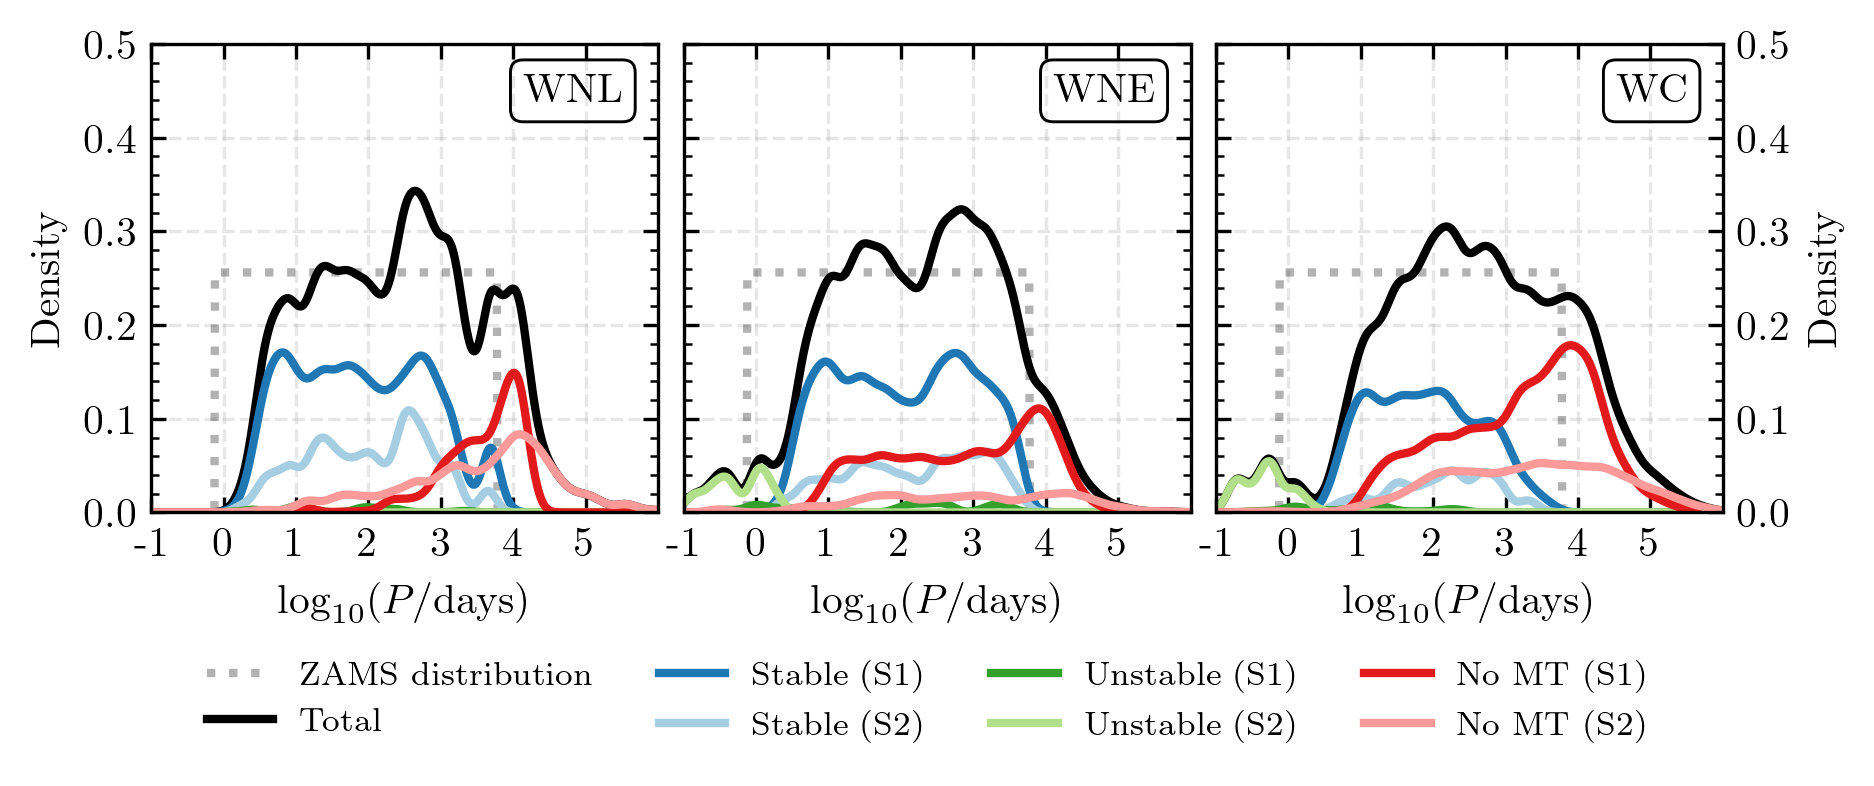

In [18]:
from posydon.popsyn.distributions import Sana12Period

fig, axes = plt.subplots(1, 3, figsize=(3.38*2, 2.535*0.8))

weights = weight_array * model_weight_array

PDF_logP = PowerLawPeriod(p_min=0.75, p_max=6000.0, slope=0.0)
x_eval = np.linspace(-1, 7, 1000)


mask = binary_mask

MT_interactions = {'Stable (S1)': S1_mask_stable,
                   'Stable (S2)': S2_mask_stable,
                   'Unstable (S1)': S1_mask_unstable,
                   'Unstable (S2)': S2_mask_unstable,
                   'No MT (S1)': S1_mask_no_MT,
                   'No MT (S2)': S2_mask_no_MT,
                   'Reverse Stable (S1)': S1_mask_reverse_stable,}


colours = Colormap('colorbrewer:Paired_8')(np.linspace(0,1,8))

colours = {"Stable (S1)": colours[1],
           "Stable (S2)": colours[0],

           "Unstable (S1)": colours[3],
           "Unstable (S2)": colours[2],

           "No MT (S1)": colours[5],
           "No MT (S2)": colours[4],
           
           "Reverse Stable (S1)": colours[7],
           }


flatP = PDF_logP.pdf(10**x_eval)
for ax in axes:
    ax.plot(10**x_eval, flatP, ls=':',  color='black', linewidth=2, alpha=0.3, 
         label=f'ZAMS distribution')



# plot WNL
kde = gaussian_kde(np.log10(period_array[mask & WNL]), weights=weights[mask & WNL], bw_method=0.1)
kde_eval = kde(x_eval)
axes[0].plot(10**x_eval, kde_eval, color='black', label='Total', linewidth=2)

# get covariance
cho_cov = kde.cho_cov

# different MT interactions
print("WNL:", weights[mask & WNL].sum()/weights[mask & (WNL | WNE | WC)].sum())
total = 0
not_used_mask = np.ones_like(mask, dtype=bool)  # Track which data points have been used in KDEs
for label, mt_mask in MT_interactions.items():
    if np.sum(weights[mask & WNL & mt_mask]) == 0:
        continue  # Skip if no data points for this interaction type
    kde = gaussian_kde(np.log10(period_array[mask & WNL & mt_mask]), weights=weights[mask & WNL & mt_mask], bw_method=0.1)
    kde.cho_cov = cho_cov # use same covariance for all KDEs to ensure fair comparison
    kde_eval = kde(x_eval)
    fraction = np.sum(weights[mask & WNL & mt_mask]) / np.sum(weights[mask & WNL])
    total += fraction
    print(f"{label}: {fraction:.3f}")
    axes[0].plot(10**x_eval, kde_eval*fraction, label=label, linewidth=2, color=colours[label])

# Plot WNE
kde = gaussian_kde(np.log10(period_array[mask & WNE]), weights=weights[mask & WNE], bw_method=0.1)
cho_cov = kde.cho_cov # get covariance to use for all WNE KDEs
kde_eval = kde(x_eval)
axes[1].plot(10**x_eval, kde_eval, color='black', label='Total', linewidth=2)

print("WNE:", weights[mask & WNE].sum()/weights[mask & (WNL | WNE | WC)].sum())
for label, mt_mask in MT_interactions.items():
    if np.sum(weights[mask & WNE & mt_mask]) == 0:
        continue  # Skip if no data points for this interaction type
    kde = gaussian_kde(np.log10(period_array[mask & WNE & mt_mask]), weights=weights[mask & WNE & mt_mask], bw_method=0.1)
    kde.cho_cov = cho_cov # use same covariance for all KDEs to ensure fair comparison
    kde_eval = kde(x_eval)
    fraction = np.sum(weights[mask & WNE & mt_mask]) / np.sum(weights[mask & WNE])
    print(f"{label}: {fraction:.3f}")
    axes[1].plot(10**x_eval, kde_eval*fraction, label=label, linewidth=2, color=colours[label])


# plot WC
kde = gaussian_kde(np.log10(period_array[mask & WC]), weights=weights[mask & WC], bw_method=0.1)
cho_cov = kde.cho_cov # get covariance to use for all WC KDEs
kde_eval = kde(x_eval)
axes[2].plot(10**x_eval, kde_eval, color='black', label='Total', linewidth=2)

print("WC:", weights[mask & WC].sum()/weights[mask & (WNL | WNE | WC)].sum())
for label, mt_mask in MT_interactions.items():
    if np.sum(weights[mask & WC & mt_mask]) == 0:
        continue  # Skip if no data points for this interaction type
    kde = gaussian_kde(np.log10(period_array[mask & WC & mt_mask]), weights=weights[mask & WC & mt_mask], bw_method=0.1)
    kde.cho_cov = cho_cov # use same covariance for all KDEs to ensure fair comparison
    kde_eval = kde(x_eval)
    fraction = np.sum(weights[mask & WC & mt_mask]) / np.sum(weights[mask & WC])
    print(f"{label}: {fraction:.3f}")
    axes[2].plot(10**x_eval, kde_eval*fraction, label=label, linewidth=2, color=colours[label])


# Housekeeping for layout

for ax in axes:
    ax.set_xlabel('$\log_{10}(P/\mathrm{days})$')
    ax.set_xscale('log')
    ax.set_xlim(1e-1, 1e6)
    ax.set_xticks([0.1, 1, 10, 100, 1000, 10000, 100000])
    ax.set_xticklabels(['-1', '0', '1', '2', '3', '4', '5'])
    ax.set_ylim(0, 0.5)
    ax.grid(True, which='major', ls='--', alpha=0.3)
    

axes[0].set_ylabel('Density')
axes[1].legend(loc='upper left', bbox_to_anchor=(-1, -0.25), ncol=4)

axes[1].set_yticklabels([])
# move ytick label to right side for right plot
axes[-1].set_ylabel('Density')
axes[-1].yaxis.set_label_position("right")
axes[-1].yaxis.set_tick_params(left=True, right=True, labelleft=False, labelright=True)

axes[0].text(0.93, 0.9, 'WNL', transform=axes[0].transAxes, ha='right', va='center',
             bbox=dict(facecolor='none', edgecolor='black', boxstyle='round, pad=0.3', lw=0.7))
axes[1].text(0.93, 0.9, 'WNE', transform=axes[1].transAxes, ha='right', va='center',
             bbox=dict(facecolor='none', edgecolor='black', boxstyle='round, pad=0.3', lw=0.7))
axes[2].text(0.93, 0.9, 'WC', transform=axes[2].transAxes, ha='right', va='center',
             bbox=dict(facecolor='none', edgecolor='black', boxstyle='round, pad=0.3', lw=0.7))

plt.subplots_adjust(wspace=0.05)

figure_paths = '/Users/max/Documents/projects/WR_population/figure_scripts/figures/'
plt.savefig(figure_paths + 'pdf/MW_subtype_period_distributions_MT.pdf', bbox_inches='tight')
plt.savefig(figure_paths + 'png/MW_subtype_period_distributions_MT.png', bbox_inches='tight', dpi=300)
plt.show()

# Investigate specific models around 10^{2.5} days because they create some sort of peak.

In [19]:
mask = (period_array >10**(2.5)) & (period_array < 10**(3))

In [20]:
period_array[binary_mask & (WNL | WNE | WC) & mask & S1_mask_stable]

print(np.unique(key_array[binary_mask & (WNL | WNE | WC) & mask & S1_mask_stable]))

[   130    131    187 ... 299921 299959 299987]


state                                            detached
event                                                ZAMS
time                                                  0.0
orbital_period                                   3.866083
eccentricity                                          0.0
lg_mtransfer_rate                                     NaN
step_names                                   initial_cond
step_times                                            0.0
S1_state                            H-rich_Core_H_burning
S1_mass                                         16.718077
S1_log_R                                              0.0
S1_log_L                                              NaN
S1_lg_mdot                                            NaN
S1_he_core_mass                                       0.0
S1_he_core_radius                                     NaN
S1_co_core_mass                                       NaN
S1_co_core_radius                                     NaN
S1_center_h1  

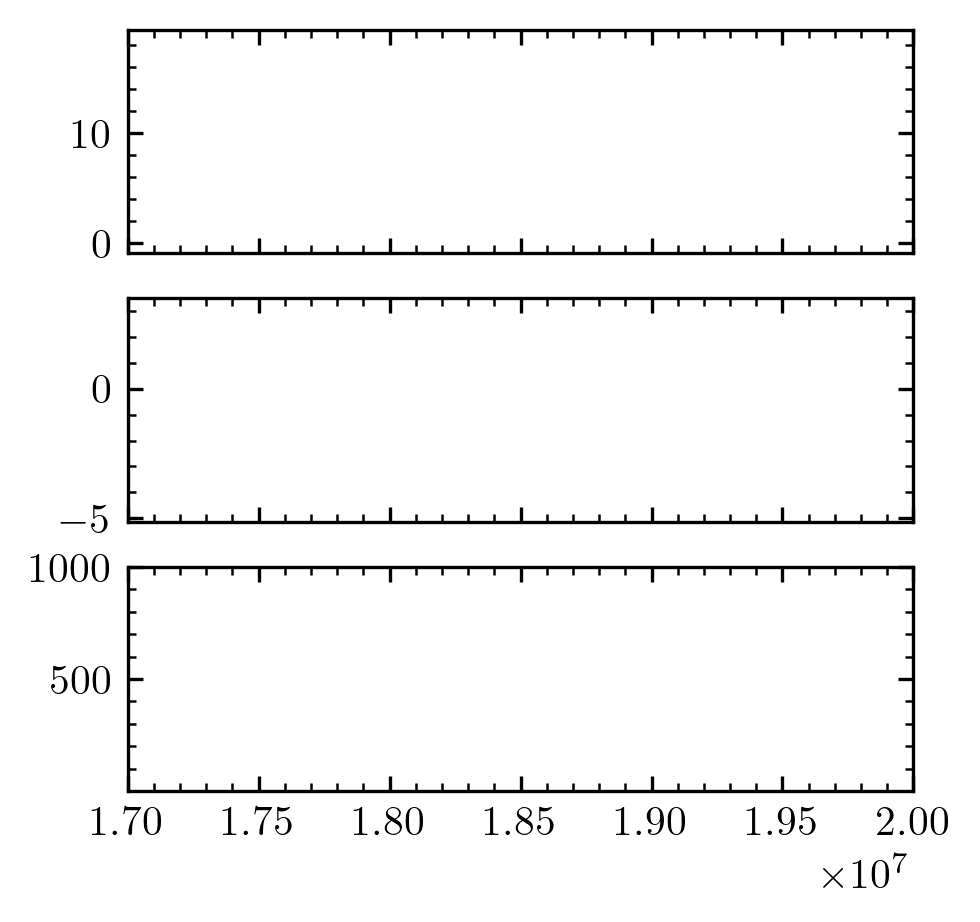

In [21]:
fig, axes = plt.subplots(3, 1, figsize=(3.38, 2.535*1.3), sharex=True)
model = pop.history[8]

axes[0].plot(model['time'], model['S1_mass'], label='S1_mass')
axes[0].plot(model['time'], model['S2_mass'], label='S2_mass')
axes[0].plot(model['time'], model['S1_he_core_mass'], label='S1_he_core_mass')

axes[1].plot(model['time'], model['S1_log_R'], label='S1_log_R')
axes[1].plot(model['time'], model['S2_log_R'], label='S2_log_R')


axes[2].plot(model['time'], model['orbital_period'], label='orbital_period')
axes[2].set_ylim(1, 1000)
axes[0].set_xlim(1.7e7,2e7)

print(pop.history[8].iloc[0])
plt.show()

In [22]:
pop.history[8].iloc[60:90]

,state,event,time,orbital_period,eccentricity,lg_mtransfer_rate,step_names,step_times,S1_state,S1_mass,...,S2_he_core_mass,S2_he_core_radius,S2_co_core_mass,S2_co_core_radius,S2_center_h1,S2_center_he4,S2_surface_h1,S2_surface_he4,S2_surf_avg_omega_div_omega_crit,S2_spin
binary_index,,,,,,,,,,,,,,,,,,,,,
8,merged,oMerging1,1.079125e+07,1.002248e+99,0.0,NaN,NaN,NaN,H-rich_Core_H_burning,18.384639,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,merged,oMerging1,1.082434e+07,1.002313e+99,0.0,NaN,NaN,NaN,H-rich_Core_H_burning,18.382245,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,merged,oMerging1,1.085743e+07,1.002378e+99,0.0,NaN,NaN,NaN,H-rich_Core_H_burning,18.379857,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,merged,oMerging1,1.089052e+07,1.002443e+99,0.0,NaN,NaN,NaN,H-rich_Core_H_burning,18.377475,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,merged,oMerging1,1.092361e+07,1.002508e+99,0.0,NaN,NaN,NaN,H-rich_Core_H_burning,18.375101,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,merged,oMerging1,1.095670e+07,1.002573e+99,0.0,NaN,NaN,NaN,H-rich_Core_H_burning,18.372734,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,merged,oMerging1,1.098979e+07,1.002637e+99,0.0,NaN,NaN,NaN,H-rich_Core_H_burning,18.370375,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,merged,oMerging1,1.102288e+07,1.002701e+99,0.0,NaN,NaN,NaN,H-rich_Core_H_burning,18.368025,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,merged,oMerging1,1.105597e+07,1.002765e+99,0.0,NaN,NaN,NaN,H-rich_Core_H_burning,18.365688,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [23]:
mt_hist = pop.oneline['mt_history_HMS_HMS']


# S1_stable_indices = set(np.where(HMS_HMS_interaction == 'stable_MT')[0])
# S1_unstable_indices = set(np.where(HMS_HMS_interaction == 'unstable_MT')[0])
# S1_reverse_stable_indices = set(np.where(HMS_HMS_interaction == 'reverse_stable_MT')[0])
# S1_no_MT_indices = set(np.where((HMS_HMS_interaction == 'no_MT') | pd.isna(HMS_HMS_interaction))[0])

# # S1 interaction masks - only apply to S1 entries
# S1_entries = (star_array == 'S1')
# S1_mask_stable = S1_entries & np.isin(key_array, np.array(list(S1_stable_indices)))


KeyboardInterrupt: 

In [ ]:
S1_entries = (star_array == 'S1')
S1_last_postMS_indices = set(np.where(mt_hist == 'Last stable RLOF during postMS')[0])

S1_mask_postMS = S1_entries & np.isin(key_array, np.array(list(S1_last_postMS_indices)))


Reverse Stable (S1): 0.292


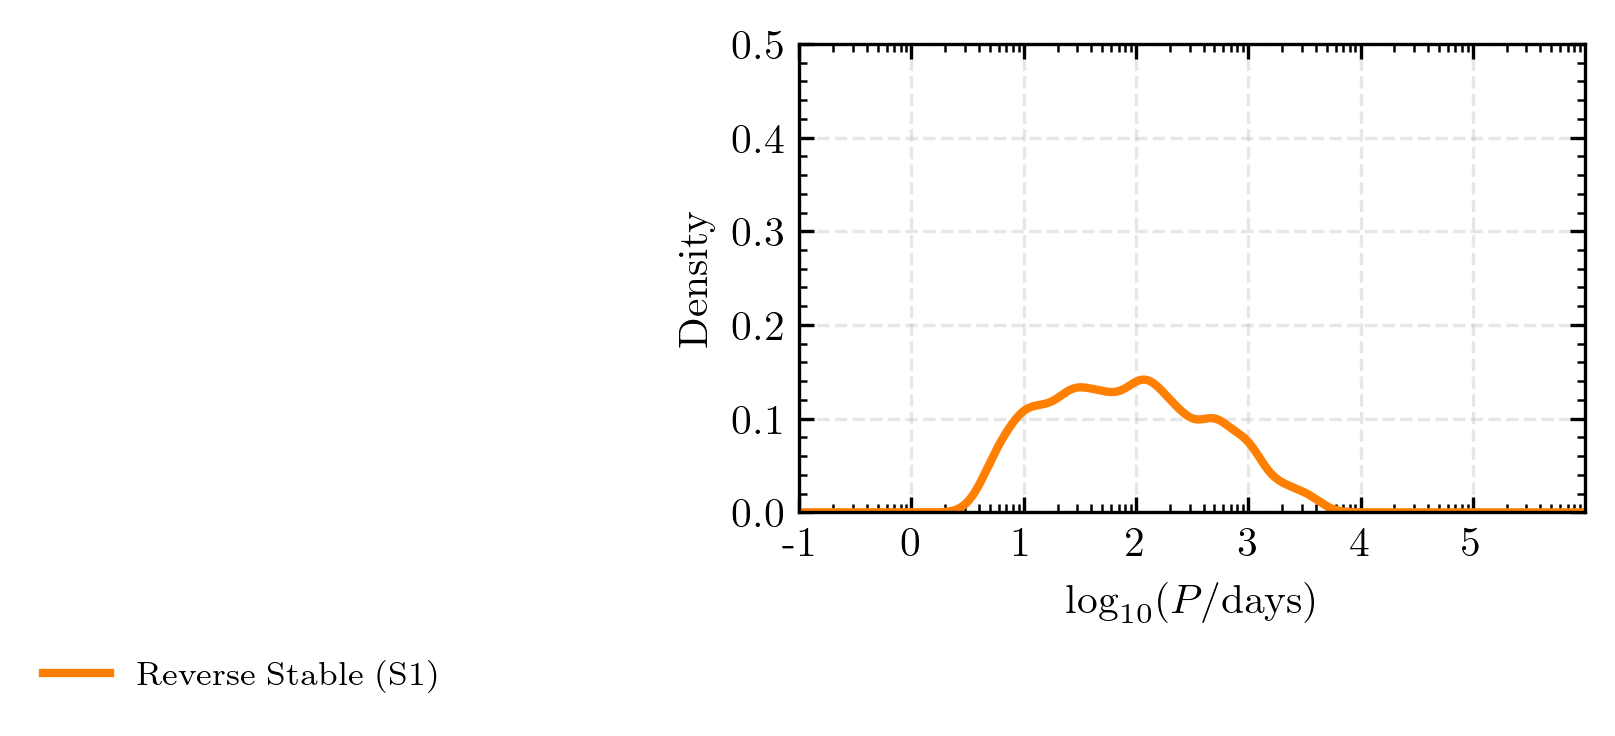

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(3.38, 2.535*0.8))

kde = gaussian_kde(np.log10(period_array[mask & WC & S1_mask_postMS]), weights=weights[mask & WC & S1_mask_postMS], bw_method=0.1)
kde.cho_cov = cho_cov # use same covariance for all KDEs to ensure fair comparison
kde_eval = kde(x_eval)
fraction = np.sum(weights[mask & WC & S1_mask_postMS]) / np.sum(weights[mask & WC])
print(f"{label}: {fraction:.3f}")
ax.plot(10**x_eval, kde_eval*fraction, label=label, linewidth=2, color=colours[label])

ax.set_xlabel('$\log_{10}(P/\mathrm{days})$')
ax.set_xscale('log')
ax.set_xlim(1e-1, 1e6)
ax.set_xticks([0.1, 1, 10, 100, 1000, 10000, 100000])
ax.set_xticklabels(['-1', '0', '1', '2', '3', '4', '5'])
ax.set_ylim(0, 0.5)
ax.grid(True, which='major', ls='--', alpha=0.3)
    

ax.set_ylabel('Density')
ax.legend(loc='upper left', bbox_to_anchor=(-1, -0.25), ncol=4)





In [115]:
mt_hist.value_counts()

mt_history_HMS_HMS                      
Last stable RLOF during postMS              34152
Unstable contact phase                      20630
Unstable RLOF during postMS                 18925
no RLOF                                      6965
Last stable RLOF during stripped He star     6599
Unstable RLOF during MS                      4144
Stable reverse mass-transfer phase           1057
Unstable reverse mass-transfer phase          926
Unstable RLOF during stripped He star         543
Stable contact phase                          535
Last stable RLOF during MS                    158
Name: count, dtype: int64

# Other investigations